/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - loss: 2580.3433 - mae: 40.5731 - val_loss: 2466.7083 - val_mae: 41.0625
Epoch 2/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 2564.5842 - mae: 40.4407 - val_loss: 2452.3179 - val_mae: 40.9416
Epoch 3/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 2545.6099 - mae: 40.2813 - val_loss: 2435.3535 - val_mae: 40.8036
Epoch 4/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 2523.0007 - mae: 40.0910 - val_loss: 2414.2026 - val_mae: 40.6306
Epoch 5/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 2496.0569 - mae: 39.8603 - val_loss: 2389.1587 - val_mae: 40.4247
Epoch 6/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 2461.8872 - mae: 39.5770 - val_loss: 2359.4651 - val_mae: 40.1734
Epoch 7/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 2423.4844 - mae: 39.2355 - val_loss: 2323.0454 - val_mae: 39.8596
Epoch 8/50
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 2377.5374 - mae: 38.8256 - val_loss: 2278.8994 - val_mae: 39.4684
Epoch 9

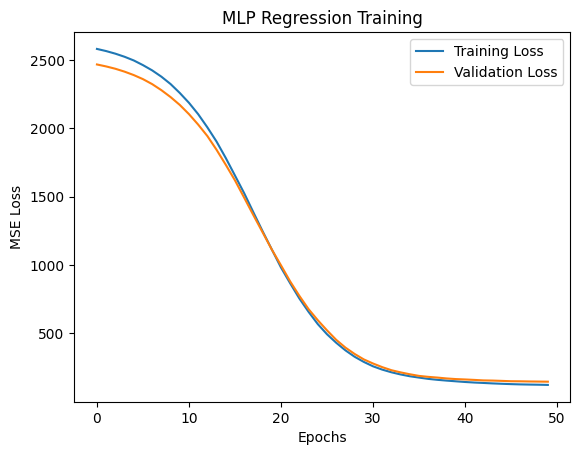

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 163.8716 - mae: 10.4150  
Test MSE: 163.8716278076172
Test MAE: 10.414978981018066
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step
Actual Values: [ 45.44738048  16.08190078  50.14531122 -74.0430498   85.21256496]
Predicted Values: [ 59.220875  37.34035   55.95253  -62.04222   70.72169 ]


In [1]:

# Step 1: Import required libraries
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_regression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

# Step 2: Generate the dataset
X, Y = make_regression(n_samples=500,
                       n_features=4,
                       noise=10,
                       random_state=42)

# Step 3: Normalize the input data
scaler = StandardScaler()
X = scaler.fit_transform(X)

# Step 4: Split the dataset
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.2, random_state=42
)

# Step 5: Build the MLP model
model = Sequential([
    Dense(16, activation='relu', input_shape=(4,)),
    Dense(8, activation='relu'),
    Dense(1, activation='linear')
])

# Step 6: Compile the model
model.compile(optimizer='adam',
              loss='mean_squared_error',
              metrics=['mae'])

# Step 7: Train the model
history = model.fit(X_train, Y_train,
                    epochs=50,
                    batch_size=16,
                    validation_split=0.2,
                    verbose=1)

# Step 8: Plot training and validation loss
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('MSE Loss')
plt.title('MLP Regression Training')
plt.legend()
plt.show()

# Step 9: Test the model
loss, mae = model.evaluate(X_test, Y_test)
print("Test MSE:", loss)
print("Test MAE:", mae)

# Step 10: Predict continuous values
predictions = model.predict(X_test[:5])

print("Actual Values:", Y_test[:5])
print("Predicted Values:", predictions.flatten())


Epoch 1/50


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 33ms/step - accuracy: 0.0938 - loss: 1.3996 - val_accuracy: 0.2500 - val_loss: 1.2226
Epoch 2/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.1354 - loss: 1.2955 - val_accuracy: 0.3333 - val_loss: 1.1436
Epoch 3/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.1875 - loss: 1.2147 - val_accuracy: 0.5000 - val_loss: 1.0745
Epoch 4/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.2500 - loss: 1.1499 - val_accuracy: 0.5417 - val_loss: 1.0174
Epoch 5/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.2917 - loss: 1.0965 - val_accuracy: 0.5833 - val_loss: 0.9704
Epoch 6/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.3333 - loss: 1.0521 - val_accuracy: 0.6667 - val_loss: 0.9230
Epoch 7/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.4375 - loss: 1.0124 - val_accuracy: 0.7500 - val_loss: 0.8806
Epoch 8/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.5521 - loss: 0.9778 - val_accuracy: 0.7500 - val_loss: 0.83

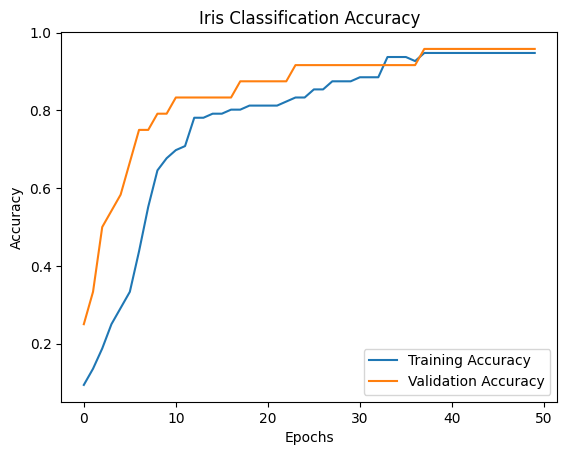

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 181ms/step - accuracy: 0.9667 - loss: 0.1742
Test Loss: 0.17420326173305511
Test Accuracy: 0.9666666388511658
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step
Predicted Classes: [1 0 2 1 1]
Actual Classes: [1 0 2 1 1]
Predicted Flower Names:
versicolor
setosa
virginica
versicolor
versicolor


In [2]:

# Step 1: Import required libraries
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.utils import to_categorical

# Step 2: Load the Iris dataset
iris = load_iris()
X = iris.data
Y = iris.target

# Step 3: Normalize the input data
scaler = StandardScaler()
X = scaler.fit_transform(X)

# Step 4: Convert output into categorical format
Y = to_categorical(Y, num_classes=3)

# Step 5: Split the dataset
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.2, random_state=42
)

# Step 6: Build the MLP model
model = Sequential([
    Dense(16, activation='relu', input_shape=(4,)),
    Dense(8, activation='relu'),
    Dense(3, activation='softmax')
])

# Step 7: Compile the model
model.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])

# Step 8: Train the model
history = model.fit(X_train, Y_train,
                    epochs=50,
                    batch_size=8,
                    validation_split=0.2,
                    verbose=1)

# Step 9: Plot training accuracy
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title('Iris Classification Accuracy')
plt.legend()
plt.show()

# Step 10: Test the model
loss, accuracy = model.evaluate(X_test, Y_test)
print("Test Loss:", loss)
print("Test Accuracy:", accuracy)

# Step 11: Predict flower classes
predictions = model.predict(X_test[:5])

predicted_classes = np.argmax(predictions, axis=1)
actual_classes = np.argmax(Y_test[:5], axis=1)

print("Predicted Classes:", predicted_classes)
print("Actual Classes:", actual_classes)

# Display flower names
print("Predicted Flower Names:")
for i in predicted_classes:
    print(iris.target_names[i])
